# W51 saturated-pixel recovery: progress report

2026-10-16

**Summary**

* The first full training-set run (June 2026, 480 tables) carries two label bugs: saturated pixels of neighbouring stars received the fitted star's flux, and `fluxerr` was stored as a variance. Both are fixed in `py/making_training_set.py`; the tables need to be regenerated.
* Saturated regions that merge a star with extended emission are rejected by a new `area_ratio` check. Two residual-based checks were tested on real data and did not separate good from bad sources.
* Uniform `sat_level` classes are feasible at roughly 137,000 rows per level with per-source caps. MIRI pixels saturated in group 0 carry no flux information in their ramp.
* The 4QPM panes give an unsaturated, PSF-free truth for MIRI, but only for pixels first saturated in groups 2-4 (and 4,463 rows in group 1). No unsaturated pane covers a pixel saturated in group 0.

## 1. Goal and pipeline

A gradient-boosting model will predict the true flux of saturated JWST NIRCam/MIRI pixels from the shape of their non-linear ramp. Labels come from PSF fits of partially saturated stars: the unsaturated sidelobes constrain the flux of the saturated core.

1. Flag saturated pixels from the `cal` DQ array and group them into connected sources.
2. For each source, fit a stpsf `GriddedPSFModel` to an 81 px cutout with the saturated core masked.
3. Evaluate the fitted model at each saturated pixel as its ground-truth flux.
4. Pair that label with ramp features from the `ramp` file (`DN0`-`DN4`, slopes, curvatures, `sat_level`).

Code: `py/making_training_set.py`, submitted per filter by `script/run_making_training_set.sh` (10 NIRCam and 5 MIRI filters, program 6151).

In [1]:
import os, sys, glob, re, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from scipy import ndimage
from scipy.stats import spearmanr
from IPython.display import Image, display

REPO = '/blue/adamginsburg/t.yoo/w51_sat_recover'
TRAIN_DIR = '/orange/adamginsburg/w51/TaehwaYoo/w51_sat_recover'
OLD_IMG_DIR = f'{TRAIN_DIR}/cutout_img'
REPORT_IMG_DIR = f'{TRAIN_DIR}/progress_report_img'
PANE_DIR = '/blue/adamginsburg/t.yoo/w51_miri_cal_claude/work'
os.makedirs(REPORT_IMG_DIR, exist_ok=True)
pd.set_option('display.width', 160)

## 2. Audit of the June training set

All 480 tables in `TRAIN_DIR` were written on 2026-06-26, before the fixes in section 3. A source is identified here by its file and fitted star flux (`psf_star_flux` is constant over a source's rows).

In [2]:
cols = ['flux', 'fluxerr', 'sat_level', 'instrument', 'wavelength', 'dist_to_peak', 'psf_star_flux',
        'DN0', 'DN1', 'DN2', 'DN3', 'DN4', 'nl_strength']
frames = []
for fn in sorted(glob.glob(f'{TRAIN_DIR}/*_ml_training.fits')):
    t = Table.read(fn)
    if len(t) == 0:
        continue
    d = t[cols].to_pandas()
    d['file'] = os.path.basename(fn)
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
df['source_id'] = df['file'] + '|' + df['psf_star_flux'].round(4).astype(str)
df['instrument'] = np.where(df['instrument'] == 0, 'NIRCam', 'MIRI')
print(f'{len(frames)} non-empty tables, {len(df):,} rows, {df.source_id.nunique():,} sources')

471 non-empty tables, 2,048,321 rows, 25,662 sources


In [3]:
area = df.groupby('source_id').size()
# fluxerr in these tables is a variance; sqrt gives the per-pixel error, and flux/err is then the star-level SNR
df['snr'] = df['flux'] / np.sqrt(df['fluxerr'])
src_snr = df.groupby('source_id')['snr'].median()
rho, p = spearmanr(area.values, src_snr.loc[area.index].values)
dn = df[['DN0', 'DN1', 'DN2', 'DN3', 'DN4']].to_numpy()
nonmono = ~np.all(np.diff(dn, axis=1) >= 0, axis=1)

audit = pd.DataFrame({
    'value': [
        f"{df.dist_to_peak.median():.1f} px / {df.dist_to_peak.max():.0f} px",
        f"{(df.dist_to_peak < 5).mean():.0%}",
        f"{(df.flux / df.fluxerr).median():.1e}",
        f"{area.min()} / {area.median():.0f} / {area.max():,} px",
        f"{rho:.2f}",
        f"{nonmono.mean():.0%}",
        f"{(df.nl_strength < 0).mean():.0%}",
    ]},
    index=['dist_to_peak median / max',
           'rows within 5 px of the fit center',
           'flux / fluxerr (stored column), median',
           'saturated area per source, min / median / max',
           'Spearman rho, area vs fit SNR',
           'rows with non-monotonic DN0-DN4',
           'rows with nl_strength < 0'])
audit

,value
dist_to_peak median / max,21.7 px / 116 px
rows within 5 px of the fit center,40%
"flux / fluxerr (stored column), median",2.3e-05
"saturated area per source, min / median / max","6 / 45 / 11,452 px"
"Spearman rho, area vs fit SNR",-0.46
rows with non-monotonic DN0-DN4,9%
rows with nl_strength < 0,28%


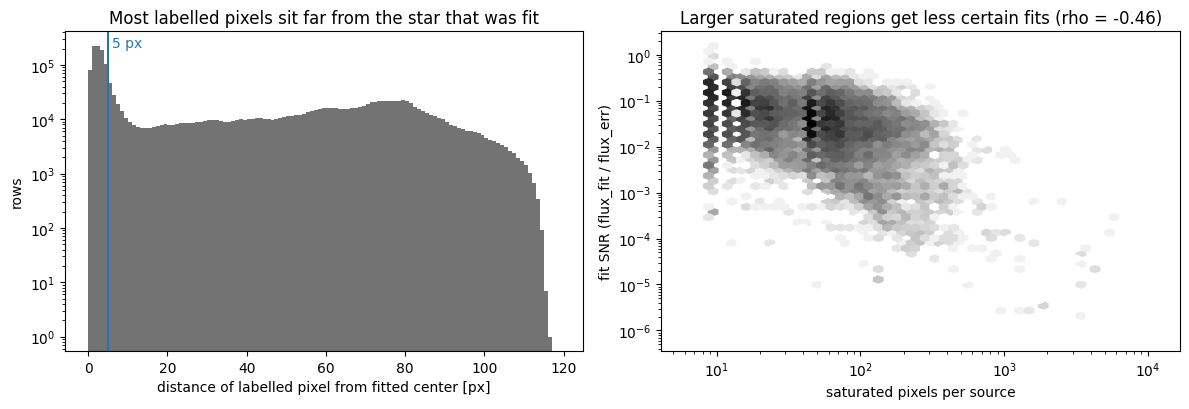

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(df.dist_to_peak, bins=np.arange(0, 120, 1), color='0.45')
ax.axvline(5, color='C0', lw=1.5)
ax.text(6, ax.get_ylim()[1] * 0.9, '5 px', color='C0')
ax.set_yscale('log')
ax.set_xlabel('distance of labelled pixel from fitted center [px]')
ax.set_ylabel('rows')
ax.set_title('Most labelled pixels sit far from the star that was fit')

ax = axes[1]
ok = np.isfinite(src_snr.loc[area.index].values) & (src_snr.loc[area.index].values > 0)
ax.hexbin(area.values[ok], src_snr.loc[area.index].values[ok], xscale='log', yscale='log',
          gridsize=50, bins='log', cmap='Greys')
ax.set_xlabel('saturated pixels per source')
ax.set_ylabel('fit SNR (flux_fit / flux_err)')
ax.set_title(f'Larger saturated regions get less certain fits (rho = {rho:.2f})')
plt.tight_layout()

**Reading.** Only 40% of labelled rows lie within 5 px of the fitted center, and the tail reaches 116 px. Every saturated pixel inside the 81 px cutout received the fitted star's model flux, including pixels of other stars. The stored `fluxerr` is a sum of squares, so `flux/fluxerr` is meaningless (median ~1e-5). Fit confidence falls as the saturated area grows.

## 3. Code changes

A copy of `making_training_set.py` from before the last round of edits is at `py/making_training_set.py.bak_20260911_165100`.

| Change | What it does |
| --- | --- |
| Restrict labels to the fitted source | `idx_saturated_in_cutout &= (sources[y0:y1, x0:x1] == ii + 1)`, so only pixels of the fitted connected component are labelled |
| `fluxerr = sqrt(model_err)` | Stores a standard deviation on the same scale as `flux` |
| `area_ratio` filter (default 8.0) | Skips a source when its saturated area exceeds 8x the footprint its own fitted model produces above the cutout's 99th percentile; stored as a column |
| `sidelobe_residual_snr` column | Residual flux in an annulus sized from `area_saturated`; stored for inspection, does not filter (section 5) |
| Run script | Removed a stray backtick line from `run_making_training_set.sh` |

In [5]:
!git -C {REPO} status --short
!git -C {REPO} diff --stat

 M notebooks/progress_report.ipynb
?? py/making_training_set.py.bak_20260911_165100


 notebooks/progress_report.ipynb | 244 ++++++++++++++++++++++++++++++++++++++--
 1 file changed, 237 insertions(+), 7 deletions(-)


## 4. Balancing by `sat_level`

`sat_level` is the first group (0-4) in which the ramp is flagged saturated. Counts below are from the June run and will change after regeneration.

In [6]:
counts = pd.crosstab(df.sat_level, df.instrument)[['NIRCam', 'MIRI']]
counts['sources'] = df.groupby('sat_level').source_id.nunique()
counts

instrument,NIRCam,MIRI,sources
sat_level,,,
0,66626,70519,3589
1,628161,31924,11277
2,390458,46024,13260
3,368703,73239,16812
4,372667,0,19402


In [7]:
by_filter = pd.crosstab(df.wavelength.astype(int).rename('filter (um x 100)'), df.sat_level)
by_filter

sat_level,0,1,2,3,4
filter (um x 100),,,,,
140,7814,67528,30586,25202,23338
162,10589,94359,51573,37279,35199
182,11886,113969,76360,59702,55668
187,781,11174,4501,6881,18183
210,10254,89582,55311,50500,45652
335,8196,73637,50591,60692,52137
360,7529,75027,54412,54621,62866
405,895,8194,5543,5263,4583
410,5867,63750,42354,49279,51980


In [8]:
top10 = df[df.sat_level == 0].source_id.value_counts().head(10)
print(f'top 10 sources supply {top10.sum() / (df.sat_level == 0).sum():.0%} of level-0 rows')
top10.rename('level-0 rows').to_frame()

top 10 sources supply 18% of level-0 rows


,level-0 rows
source_id,
f1000w_jw06151002002_0210f_00003_mirimage_ml_training.fits|559228.4797,3406
f1000w_jw06151002002_0210f_00004_mirimage_ml_training.fits|564664.0075,3392
f1000w_jw06151002002_0210f_00001_mirimage_ml_training.fits|647851.6638,3389
f1000w_jw06151002002_0210f_00002_mirimage_ml_training.fits|767977.8016,3367
f560w_jw06151002002_0210b_00003_mirimage_ml_training.fits|1463721.6466,2428
f1280w_jw06151002002_02107_00004_mirimage_ml_training.fits|1916029.0326,2304
f1000w_jw06151002001_02105_00004_mirimage_ml_training.fits|621922.6787,1750
f1000w_jw06151002002_0210f_00001_mirimage_ml_training.fits|3024903.7715,1662
f1000w_jw06151002001_0210f_00003_mirimage_ml_training.fits|8599685.8393,1466


**Feasibility check of the recommended sampler.** Cap each (source, level) pair at 30 rows, then downsample every level to the smallest level count.

In [9]:
CAP = 30
shuf = df.sample(frac=1, random_state=0)
capped = shuf[shuf.groupby(['source_id', 'sat_level']).cumcount() < CAP]
n_per_level = capped.sat_level.value_counts().min()
balanced = capped.groupby('sat_level', group_keys=False).sample(n=n_per_level, random_state=0)
summary = pd.crosstab(balanced.sat_level, balanced.instrument)[['NIRCam', 'MIRI']]
summary['sources'] = balanced.groupby('sat_level').source_id.nunique()
top10_bal = balanced[balanced.sat_level == 0].source_id.value_counts().head(10).sum() / n_per_level
print(f'{n_per_level:,} rows per level after a cap of {CAP} per (source, level); '
      f'top 10 sources now supply {top10_bal:.1%} of level 0')
summary

62,618 rows per level after a cap of 30 per (source, level); top 10 sources now supply 0.5% of level 0


instrument,NIRCam,MIRI,sources
sat_level,,,
0,57321,5297,3589
1,61834,784,11007
2,61725,893,12529
3,61467,1151,15098
4,62618,0,16667


**Reading.**

* Level 0 limits a uniform set. F560W and F1000W rows are all level 0, and MIRI has no level-4 rows, so balance within a filter is impossible for some levels.
* The per-source cap spreads each level over many more stars, about 62,600 rows per level. MIRI then supplies only 784-5,297 rows per level, because a few MIRI sources held most of its rows; balancing within each instrument would keep more MIRI data.
* For MIRI, a pixel saturated in group 0 sits on the hard plateau (raw DN 57,000-62,000) in every read (`saturation_recovery.ipynb` in `w51_miri_cal_claude`, section 6). Its ramp features cannot predict its flux, so equal weight for level 0 trains on uninformative inputs. Whether NIRCam multi-frame groups keep some information at level 0 is open.

## 5. PSF-fit quality for large saturated regions

Calibration exposure: `jw06151002001_02105_00004_mirimage` (F1000W), 12 saturated sources, run with the current code. The model footprint is the number of model pixels above the cutout's 99th percentile, printed by the pipeline for each source that reaches that check.

In [10]:
sys.path.insert(0, f'{REPO}/py')
import making_training_set as mts

fn = '/orange/adamginsburg/jwst/w51/F1000W/pipeline/jw06151002001_02105_00004_mirimage_cal.fits'
buf = io.StringIO()
with fits.open(fn) as cal, fits.open(fn.replace('_cal.fits', '_ramp.fits')) as ramp, contextlib.redirect_stdout(buf):
    kept = mts.collect_saturated_pixels(cal, ramp, filtername='F1000W', instrument='MIRI', detector='mirimage',
                                        plot=True, fn=fn, img_save_dir=REPORT_IMG_DIR)
log = buf.getvalue()
print(f'{len(kept)} labelled pixels kept')

**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-072 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


/blue/adamginsburg/t.yoo/w51_sat_recover/py/filtering.py:31: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


201 labelled pixels kept


In [11]:
# saturated area per source, labelled exactly as in collect_saturated_pixels
dq = fits.getdata(fn, 'DQ')
sat = (dq & mts.dqflags.pixel['SATURATED']) > 0
labels, nsrc = ndimage.label(sat)
sizes = ndimage.sum_labels(sat, labels, np.arange(nsrc) + 1)
edge = np.isin(labels, np.where(sizes > 10000)[0] + 1)
sat_noedge = sat & ~ndimage.binary_dilation(edge, iterations=5)
areas = ndimage.sum_labels(sat_noedge, labels, np.arange(nsrc) + 1)


def outcome(line):
    if 'HOT' in line:
        return 'skipped: HOT pixel'
    if 'larger than the' in line:
        return 'skipped: area_ratio'
    if 'low SNR' in line:
        return 'skipped: fit SNR'
    if 'pixels above threshold' in line:
        return 'skipped: faint model'
    if 'changed the total flux' in line:
        return 'skipped: flux change > 20%'
    return 'skipped: ' + line[:40]


rows, cur = {}, None
for line in log.splitlines():
    m = re.match(r'Source (\d+): center at \(x, y\) = \((\d+), (\d+)\)', line)
    if m:
        cur = int(m.group(1))
        rows[cur] = dict(source=cur, x=int(m.group(2)), y=int(m.group(3)), area=int(areas[cur - 1]),
                         footprint=np.nan, result='kept')
        continue
    if cur is None:
        continue
    m = re.match(r'Number of pixels above threshold \(.*\): ([\d.]+)', line)
    if m:
        rows[cur]['footprint'] = float(m.group(1))
    elif line.startswith('PSF photometry failed') and rows[cur]['result'] == 'kept':
        rows[cur]['result'] = 'skipped: PSF fit failed'
    elif (line.startswith('Warning') or line.startswith('Skipping')) and rows[cur]['result'] == 'kept':
        rows[cur]['result'] = outcome(line)
calib = pd.DataFrame(rows.values()).set_index('source')
calib['area_ratio'] = (calib.area / calib.footprint).round(2)
calib

,x,y,area,footprint,result,area_ratio
source,,,,,,
1,498,43,49,33.0,skipped: fit SNR,1.48
2,536,48,32,22.0,skipped: fit SNR,1.45
3,234,66,42,NaN,skipped: PSF fit failed,NaN
4,368,110,808,85.0,skipped: area_ratio,9.51
5,475,130,1777,127.0,skipped: area_ratio,13.99
6,530,148,135,20.0,kept,6.75
7,538,234,38,21.0,kept,1.81
8,742,335,9,NaN,skipped: HOT pixel,NaN
9,816,470,9,NaN,skipped: HOT pixel,NaN


Saturated mask (red contour) of every source on its `cal` cutout, to judge which saturated regions are clean stellar cores.

/blue/adamginsburg/t.yoo/from_red/miniconda3/envs/py311/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


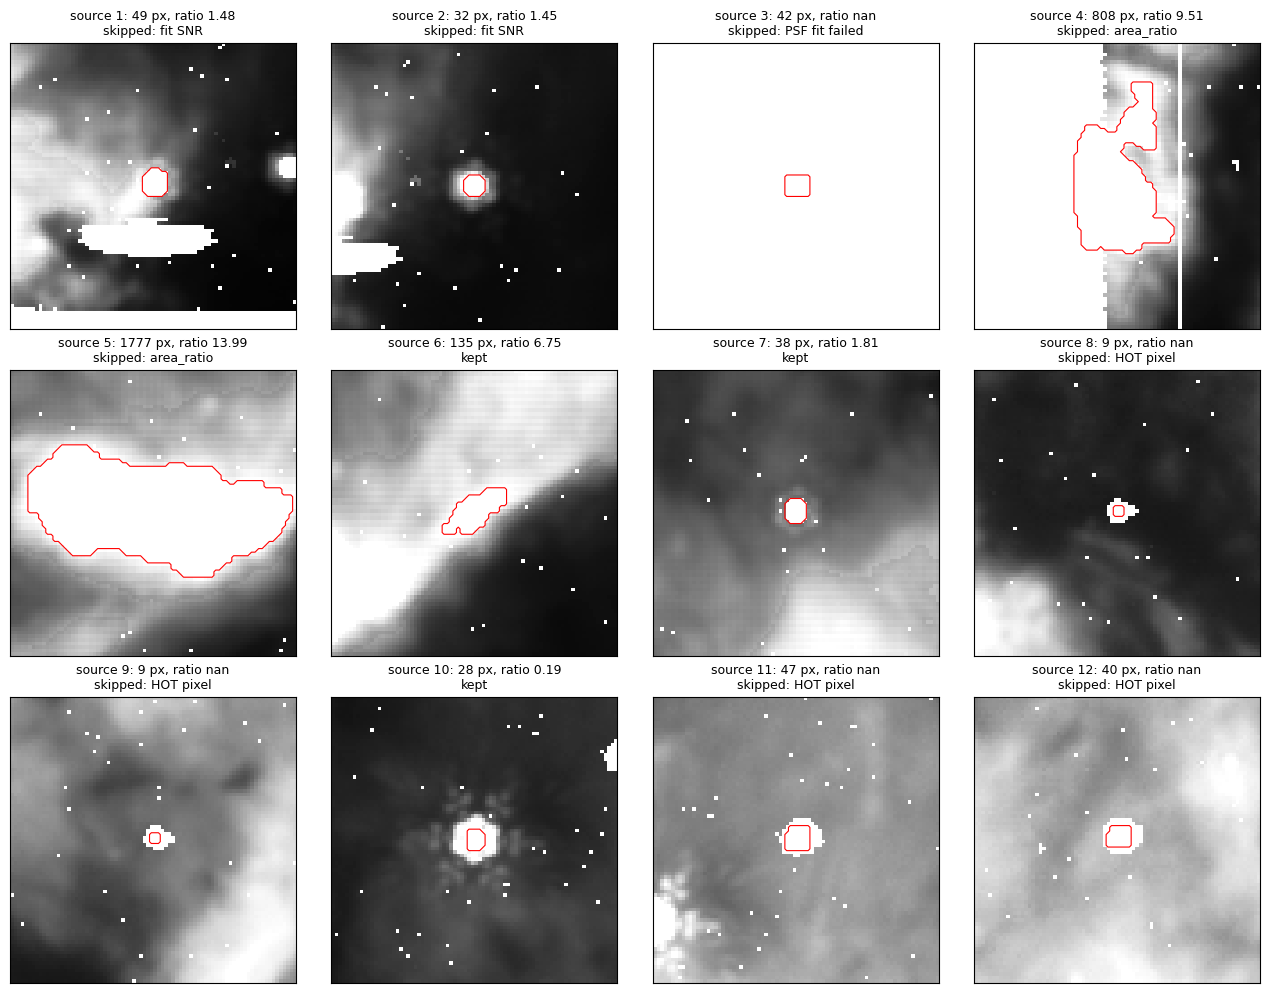

In [12]:
sci = fits.getdata(fn, 'SCI')
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, (s, r) in zip(axes.flat, calib.iterrows()):
    yc, xc = int(r.y), int(r.x)
    y0, y1 = max(0, yc - 40), min(sci.shape[0], yc + 40)
    x0, x1 = max(0, xc - 40), min(sci.shape[1], xc + 40)
    cut = sci[y0:y1, x0:x1]
    vmax = np.nanpercentile(cut, 99)
    ax.imshow(cut, origin='lower', cmap='Greys_r', vmin=0, vmax=vmax)
    ax.contour(labels[y0:y1, x0:x1] == s, levels=[0.5], colors='r', linewidths=0.8)
    ax.set_title(f'source {s}: {r.area} px, ratio {r.area_ratio}\n{r.result}', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

**Reading.**

* Rejected by `area_ratio`: source 4 (irregular, beside a masked detector region) and source 5 (a 1,777 px saturated ridge in extended emission). Neither is a stellar core.
* Kept: sources 7 and 10 are compact cores; source 10 shows the diffraction pattern. Source 6 (ratio 6.75) is an elongated streak along the edge of a bright ridge, so it is a borderline case close to the 8.0 threshold.
* Source 3 sits in a fully masked (NaN) region, so the PSF fit fails.
* Sources 8, 9, 11 and 12 are compact cores dropped by the HOT-pixel check, and sources 1 and 2 by the fit-SNR check. The HOT check removes 4 of 12 sources in this exposure and may be stricter than needed.

**Cross-star fix, same source before and after.** Left: June run (all saturated pixels in the cutout labelled). Right: current code (only the fitted source's pixels). The image is source 6; the extended saturated band in the lower left is source 5, a separate connected component.

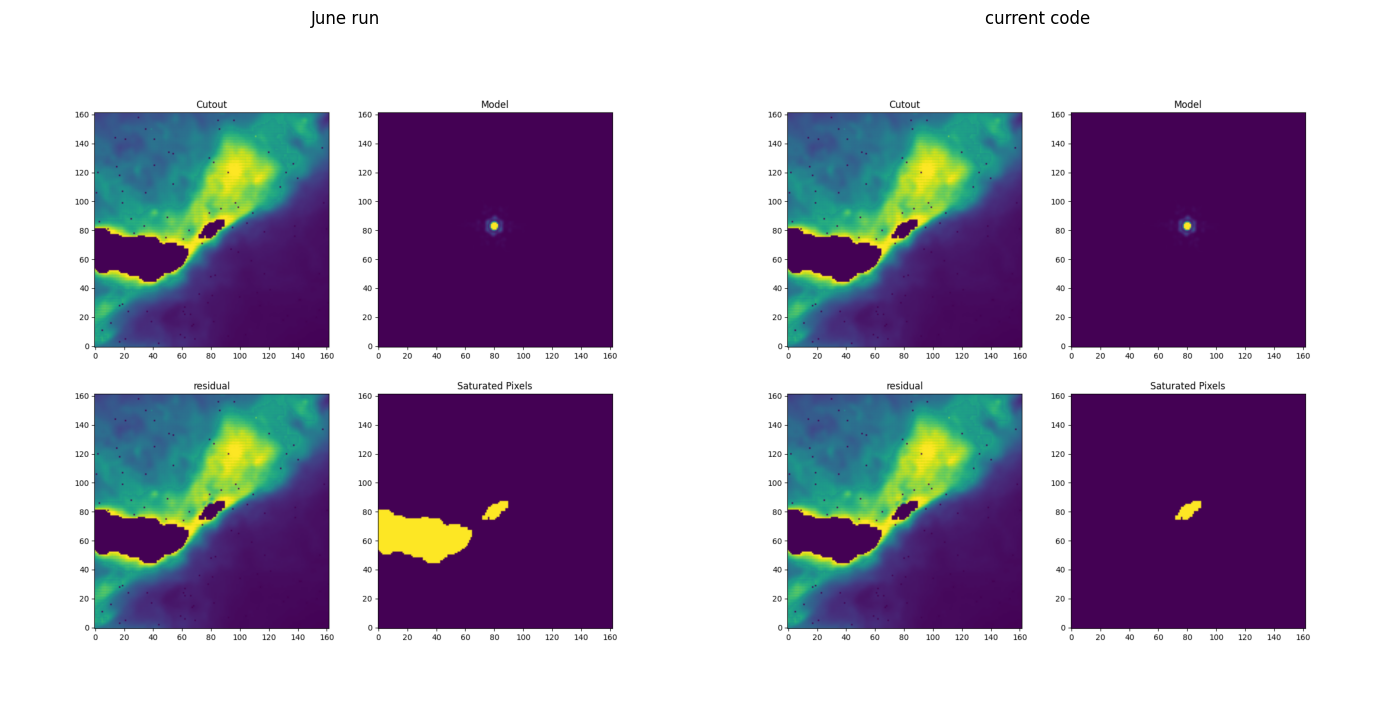

In [13]:
name = 'f1000wjw06151002001_02105_00004_mirimage_ml_training_5.png'
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, path, title in [(axes[0], f'{OLD_IMG_DIR}/{name}', 'June run'),
                        (axes[1], f'{REPORT_IMG_DIR}/{name}', 'current code')]:
    ax.imshow(plt.imread(path))
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()

**Residual-based checks tried and set aside** (same exposure, earlier calibration runs):

* **Azimuthal asymmetry of the residual** in 8 sectors around the fit center: source 4 scored 0.62, below sources 6 (0.83) and 7 (1.07).
* **Total residual flux in an annulus sized from `area_saturated`**, normalized by noise x sqrt(n): sources 6 and 7 scored 10 and 66, sources 4 and 5 scored 21 and 13, so the ranges overlap. The normalization assumes independent pixels, while W51's diffuse emission is correlated over many pixels.

The 8.0 threshold rests on 12 sources from one exposure. The current values of `sidelobe_residual_snr` for the kept sources:

In [14]:
kept[['area_ratio', 'sidelobe_residual_snr']].to_pandas().drop_duplicates().reset_index(drop=True)

,area_ratio,sidelobe_residual_snr
0,6.750000,10.335146
1,1.809524,66.102372
2,0.187919,-7.538738


## 6. Suggested features (not implemented)

* PSF model value at the pixel divided by the fitted star flux (already in memory as `model_image`)
* Per-pixel saturation threshold from the CRDS `SATURATION` reference file
* Non-linearity coefficients from the CRDS `LINEARITY` reference file
* Local background level from the fit's `LocalBackground` estimate
* Read noise and dark current at the pixel
* Amplifier ID and column within the amplifier
* Detector row and column
* Saturated-region area and compactness of the parent source

## 7. New idea: 4QPM panes as an unsaturated ground truth

In full-frame MIRI imaging, the three coronagraph panes record the same filter at 0.2-0.9 of the imager throughput. Where a pane pixel stays unsaturated and sees the same sky as a saturated imager pixel, it gives a PSF-free truth. `scripts/satrec_samples.py` in `w51_miri_cal_claude` already built per-pixel tables with that truth (`T`, background-matched MJy/sr on the i2d grid) and the first saturated group (`first`).

In [15]:
pane = {}
for F in ['F560W', 'F770W', 'F1000W', 'F1280W', 'F2100W']:
    with fits.open(f'{PANE_DIR}/satrec_{F}_pix.fits', memmap=True) as h:
        T = np.isfinite(h[1].data['T'])
        first = np.asarray(h[1].data['first'])
    pane[F] = {g: int((T & (first == g)).sum()) for g in range(5)}
pane = pd.DataFrame(pane)
pane.index.name = 'first saturated group'
pane['all MIRI'] = pane.sum(axis=1)
pane

,F560W,F770W,F1000W,F1280W,F2100W,all MIRI
first saturated group,,,,,,
0,0,0,0,0,0,0
1,1,30,0,0,4432,4463
2,7,2120,0,0,60823,62950
3,13,52238,59,665,46396,99371
4,13,61944,3047,21868,14921,101793


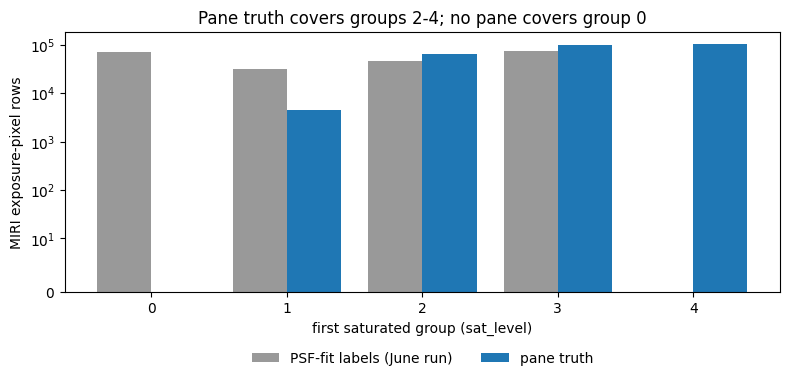

In [16]:
psf_miri = df[df.instrument == 'MIRI'].sat_level.value_counts().reindex(range(5), fill_value=0)
g = np.arange(5)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(g - 0.2, psf_miri.values, width=0.4, color='0.6', label='PSF-fit labels (June run)')
ax.bar(g + 0.2, pane['all MIRI'].values, width=0.4, color='C0', label='pane truth')
ax.set_yscale('symlog', linthresh=10)
ax.set_xticks(g)
ax.set_xlabel('first saturated group (sat_level)')
ax.set_ylabel('MIRI exposure-pixel rows')
ax.set_title('Pane truth covers groups 2-4; no pane covers group 0')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()

**Reading.**

* Group 0 has no unsaturated pane coverage in any filter: where the imager saturates in the first read, the pane saturates too. Group 1 has 4,463 rows, 4,432 of them at F2100W and only for group-0 signal <= 35,000 DN.
* For groups 2-4 the slope of the unsaturated groups already agrees with the panes to 2-8% (`saturation_recovery.ipynb`, section 4), so pane labels there mainly validate.
* What pane truth adds: labels for diffuse emission, where PSF fits fail and `area_ratio` discards the source, and an independent check of PSF-fit labels where both exist.
* Limits: pane vs imager scatters by +-5-10% (16-84%) on unsaturated pixels; the linear pane calibration runs about 6% low above ~1000 MJy/sr at F2100W; the broader pane PSF (Lyot stop) smooths compact cores; MIRI only.
* The pane tables use `jwst_new_cal_claude` ramps (linearized, `saturation` and `firstframe` skipped); `making_training_set.py` reads the original `pipeline/*_ramp.fits`. Labels and ramp features must come from one Detector1 configuration.
* The pane tables have MIRI rows first saturated in group 4, while the PSF-fit table has none. A likely cause is the candidate selection from the `cal` DQ `SATURATED` flag, which may stay unset when only group 4 (dropped by `lastframe`) saturates.

## 8. Regenerated training set (v2), 2026-10-20

`making_training_set.py` at commit `59fd1d9`, all 15 filters, written to `TRAIN_DIR/v2/`.

* **MIRI** ramps and `cal` files from `/orange/adamginsburg/w51/jwst/jwst_new_cal_claude_satstep/<F>/pipeline_4qpm/`: the `jwst_new_cal_claude` Detector1 settings (`firstframe` and `rscd` skipped, `suppress_one_group=False`) with the `saturation` step on, so saturated groups are left out of the slope fit (`w51_miri_cal_claude/run_report_satstep.ipynb`).
* **NIRCam** from the original `pipeline/` products (default Detector1, `saturation` on).
* Fixes from section 3: per-source labels, `fluxerr` as a standard deviation, `area_ratio` filter.
* New in v2: the label is PSF model + `local_bkg`. `PSFPhotometry` subtracts a local background (`LocalBackground(15, 30)`) before fitting, but the ramp records source plus background. A first v2 run without it gave MIRI label / `cal` medians of 0.60 / 0.40 / 0.28 at `sat_level` 1 / 2 / 3, falling with level as the background share grows; `local_bkg` is now also stored as a column.
* Candidates still come from the `cal` DQ `SATURATED` flag. In the satstep files it matches the ramp `GROUPDQ` for pixels first saturated in groups 0-3 and is never set for group 4 (dropped by `lastframe`), so MIRI has no level-4 rows by construction.

In [17]:
V2 = f'{TRAIN_DIR}/v2'
cols2 = cols + ['x', 'y', 'area_ratio', 'sidelobe_residual_snr', 'local_bkg']
frames = []
for fn in sorted(glob.glob(f'{V2}/*_ml_training.fits')):
    t = Table.read(fn)
    if len(t) == 0:
        continue
    d = t[cols2].to_pandas()
    d['file'] = os.path.basename(fn)
    frames.append(d)
v2 = pd.concat(frames, ignore_index=True)
v2['source_id'] = v2['file'] + '|' + v2['psf_star_flux'].round(4).astype(str)
v2['instrument'] = np.where(v2['instrument'] == 0, 'NIRCam', 'MIRI')
n_tables = len(glob.glob(f'{V2}/*_ml_training.fits'))
print(f'{n_tables} tables ({len(frames)} non-empty), {len(v2):,} rows, {v2.source_id.nunique():,} sources')

480 tables (474 non-empty), 1,179,223 rows, 31,454 sources


In [18]:
def audit_stats(d):
    a = d.groupby('source_id').size()
    return pd.Series({
        'rows': f'{len(d):,}',
        'sources': f'{d.source_id.nunique():,}',
        'dist_to_peak median / max [px]': f'{d.dist_to_peak.median():.1f} / {d.dist_to_peak.max():.0f}',
        'rows within 5 px of fit center': f'{(d.dist_to_peak < 5).mean():.0%}',
        'saturated px per source, median / max': f'{a.median():.0f} / {a.max():,}',
    })

pd.DataFrame({'June run': audit_stats(df), 'v2': audit_stats(v2)})

,June run,v2
rows,"2,048,321","1,179,223"
sources,"25,662","31,454"
dist_to_peak median / max [px],21.7 / 116,2.8 / 65
rows within 5 px of fit center,40%,87%
"saturated px per source, median / max","45 / 11,452","23 / 3,176"


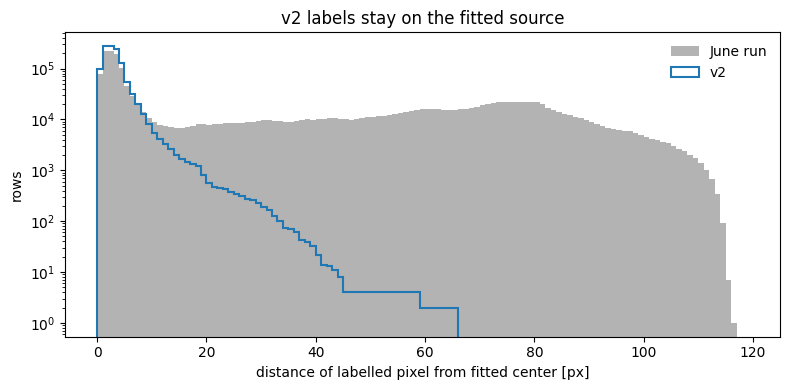

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 120, 1)
ax.hist(df.dist_to_peak, bins=bins, color='0.7', label='June run')
ax.hist(v2.dist_to_peak, bins=bins, color='C0', histtype='step', lw=1.5, label='v2')
ax.set_yscale('log')
ax.set_xlabel('distance of labelled pixel from fitted center [px]')
ax.set_ylabel('rows')
ax.set_title('v2 labels stay on the fitted source')
ax.legend(frameon=False)
plt.tight_layout()

**Why sources were skipped**, counted from the job logs (one warning per skipped source).

In [20]:
logs = sorted(glob.glob(f'{REPO}/script/making_training_set-*_46884*.log'))
reasons = {'HOT pixel': 'flagged as HOT', 'DEAD pixel': 'flagged as DEAD', 'area_ratio': 'larger than the model',
           'fit SNR': 'low SNR', 'faint model': 'pixels above threshold; skipping', 'flux change > 20%': 'changed the total flux',
           'PSF fit failed': 'PSF photometry failed'}
skip = {}
for lf in logs:
    F = re.search(r'making_training_set-(F\w+?)_', lf).group(1)
    txt = open(lf, errors='replace').read()
    row = {'candidates': len(re.findall(r'^Source \d+: center', txt, re.M))}
    row.update({k: txt.count(v) for k, v in reasons.items()})
    row['tracebacks'] = txt.count('Traceback')
    skip[F] = row
skip = pd.DataFrame(skip).T
skip['kept'] = skip['candidates'] - skip[list(reasons)].sum(axis=1)
skip.loc['all'] = skip.sum()
skip

,candidates,HOT pixel,DEAD pixel,area_ratio,fit SNR,faint model,flux change > 20%,PSF fit failed,tracebacks,kept
F1000W,536,63,2,17,106,128,0,137,0,83
F1280W,775,55,7,16,131,312,0,160,0,94
F140M,6133,1371,58,1,88,699,0,0,0,3916
F162M,6855,1390,75,2,87,773,0,0,0,4528
F182M,7845,1401,94,7,53,943,0,0,0,5347
F187N,2821,1363,36,6,46,793,0,0,0,577
F2100W,682,38,2,19,71,350,0,107,0,95
F210M,6437,1394,78,17,56,865,0,0,0,4027
F335M,7478,926,502,152,30,2091,0,0,0,3777
F360M,7020,933,508,123,21,1557,0,0,0,3878


In [21]:
counts2 = pd.crosstab(v2.sat_level, v2.instrument).reindex(columns=['NIRCam', 'MIRI'], fill_value=0)
counts2['sources'] = v2.groupby('sat_level').source_id.nunique()
counts2

instrument,NIRCam,MIRI,sources
sat_level,,,
0,37474,9046,2091
1,423704,10176,9231
2,259404,8638,11296
3,223644,9302,15726
4,197835,0,19642


**Label check against the pipeline slope.** With the `saturation` step on, a pixel that keeps at least 2 unsaturated groups (`sat_level` 2-4) gets its `cal` value from those groups alone, independent of the PSF fit. The ratio PSF-fit label / `cal` value therefore tests the labels where both exist. `sat_level` 1 pixels have a one-group value (MIRI `suppress_one_group=False`), and `sat_level` 0 pixels have no slope.

In [22]:
def cal_path(f):
    base = f.split('_', 1)[1].replace('_ml_training.fits', '_cal.fits')
    F = f.split('_', 1)[0].upper()
    if 'mirimage' in base:
        return f'/orange/adamginsburg/w51/jwst/jwst_new_cal_claude_satstep/{F}/pipeline_4qpm/{base}'
    return f'/orange/adamginsburg/jwst/w51/{F}/pipeline/{base}'

v2['cal_value'] = np.nan
for f, idx in v2.groupby('file').groups.items():
    sci = fits.getdata(cal_path(f), 'SCI')
    sub = v2.loc[idx]
    v2.loc[idx, 'cal_value'] = sci[sub.y.to_numpy(), sub.x.to_numpy()]
v2['label_over_cal'] = v2['flux'] / v2['cal_value']
v2['psf_only_over_cal'] = (v2['flux'] - v2['local_bkg']) / v2['cal_value']
ok = np.isfinite(v2.label_over_cal) & (v2.cal_value > 0)
q = (v2[ok].groupby(['instrument', 'sat_level']).label_over_cal
     .describe(percentiles=[0.16, 0.5, 0.84])[['count', '16%', '50%', '84%']])
q['median without local_bkg'] = v2[ok].groupby(['instrument', 'sat_level']).psf_only_over_cal.median()
q['median local_bkg / cal'] = (v2.local_bkg / v2.cal_value)[ok].groupby([v2.instrument[ok], v2.sat_level[ok]]).median()
q['finite cal / rows'] = (v2.assign(fin=ok).groupby(['instrument', 'sat_level']).fin.mean()).round(2)
q.round(3)

count    16%    50%    84%  median without local_bkg  median local_bkg / cal  finite cal / rows
instrument sat_level                                                                                                    
MIRI       1            9777.0  0.457  0.788  1.078                     0.601                   0.173               0.96
           2            8040.0  0.436  0.739  1.053                     0.404                   0.278               0.93
           3            8091.0  0.500  0.774  1.026                     0.281                   0.397               0.87
NIRCam     0            5504.0  0.922  1.002  1.147                     0.995                   0.005               0.15
           1          415341.0  0.805  1.006  1.240                     0.936                   0.035               0.98
           2          254857.0  0.845  0.990  1.117                     0.885                   0.051               0.98
           3          219765.0  0.856  0.988  1.094                     0.855                   0.076               0.98
           4          194281.0  0.854  0.983  1.083                     0.824                   0.102               0.98

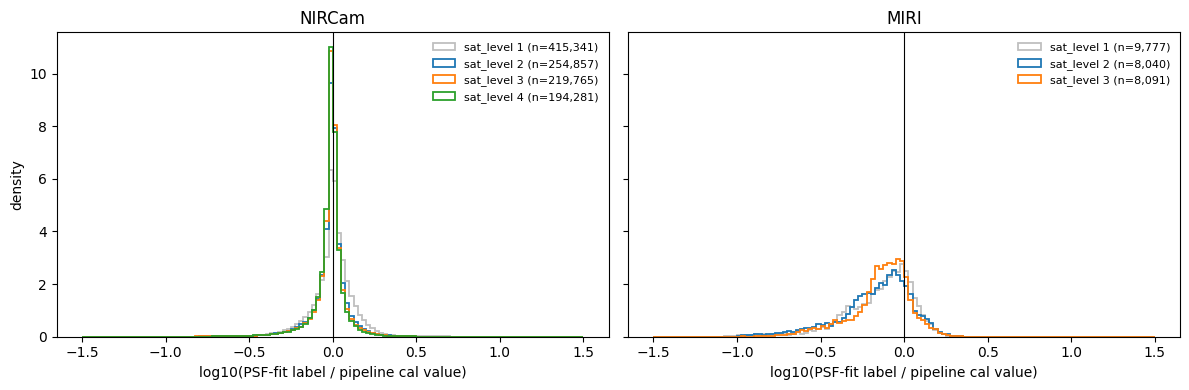

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, inst in zip(axes, ['NIRCam', 'MIRI']):
    for lvl, c in zip([1, 2, 3, 4], ['0.75', 'C0', 'C1', 'C2']):
        r = v2[ok & (v2.instrument == inst) & (v2.sat_level == lvl)].label_over_cal
        if len(r) > 20:
            ax.hist(np.log10(r), bins=np.linspace(-1.5, 1.5, 121), histtype='step', lw=1.3, color=c,
                    label=f'sat_level {lvl} (n={len(r):,})', density=True)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('log10(PSF-fit label / pipeline cal value)')
    ax.set_title(inst)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('density')
plt.tight_layout()

In [24]:
# label / cal against area_ratio, levels 2-4: does the 8.0 cut sit where the labels go bad?
m = ok & v2.sat_level.between(2, 4) & np.isfinite(v2.area_ratio)
bins_ar = [0, 1, 2, 4, 6, 8]
g = v2[m].groupby([v2[m].instrument, pd.cut(v2[m].area_ratio, bins_ar)], observed=True).label_over_cal
g.describe(percentiles=[0.16, 0.5, 0.84])[['count', '16%', '50%', '84%']].round(3)

count    16%    50%    84%
instrument area_ratio                               
MIRI       (0, 1]        1442.0  0.752  0.941  1.071
           (1, 2]        2576.0  0.640  0.874  1.072
           (2, 4]        7806.0  0.358  0.667  0.961
           (4, 6]        2350.0  0.446  0.749  1.006
           (6, 8]        1957.0  0.589  0.778  1.204
NIRCam     (0, 1]      356893.0  0.862  0.992  1.114
           (1, 2]      102481.0  0.849  0.981  1.096
           (2, 4]      119066.0  0.854  0.979  1.082
           (4, 6]       54127.0  0.834  0.970  1.070
           (6, 8]       36336.0  0.805  0.976  1.131

Example diagnostic plots from v2 (the first exposure per detector is plotted).

3852 diagnostic plots


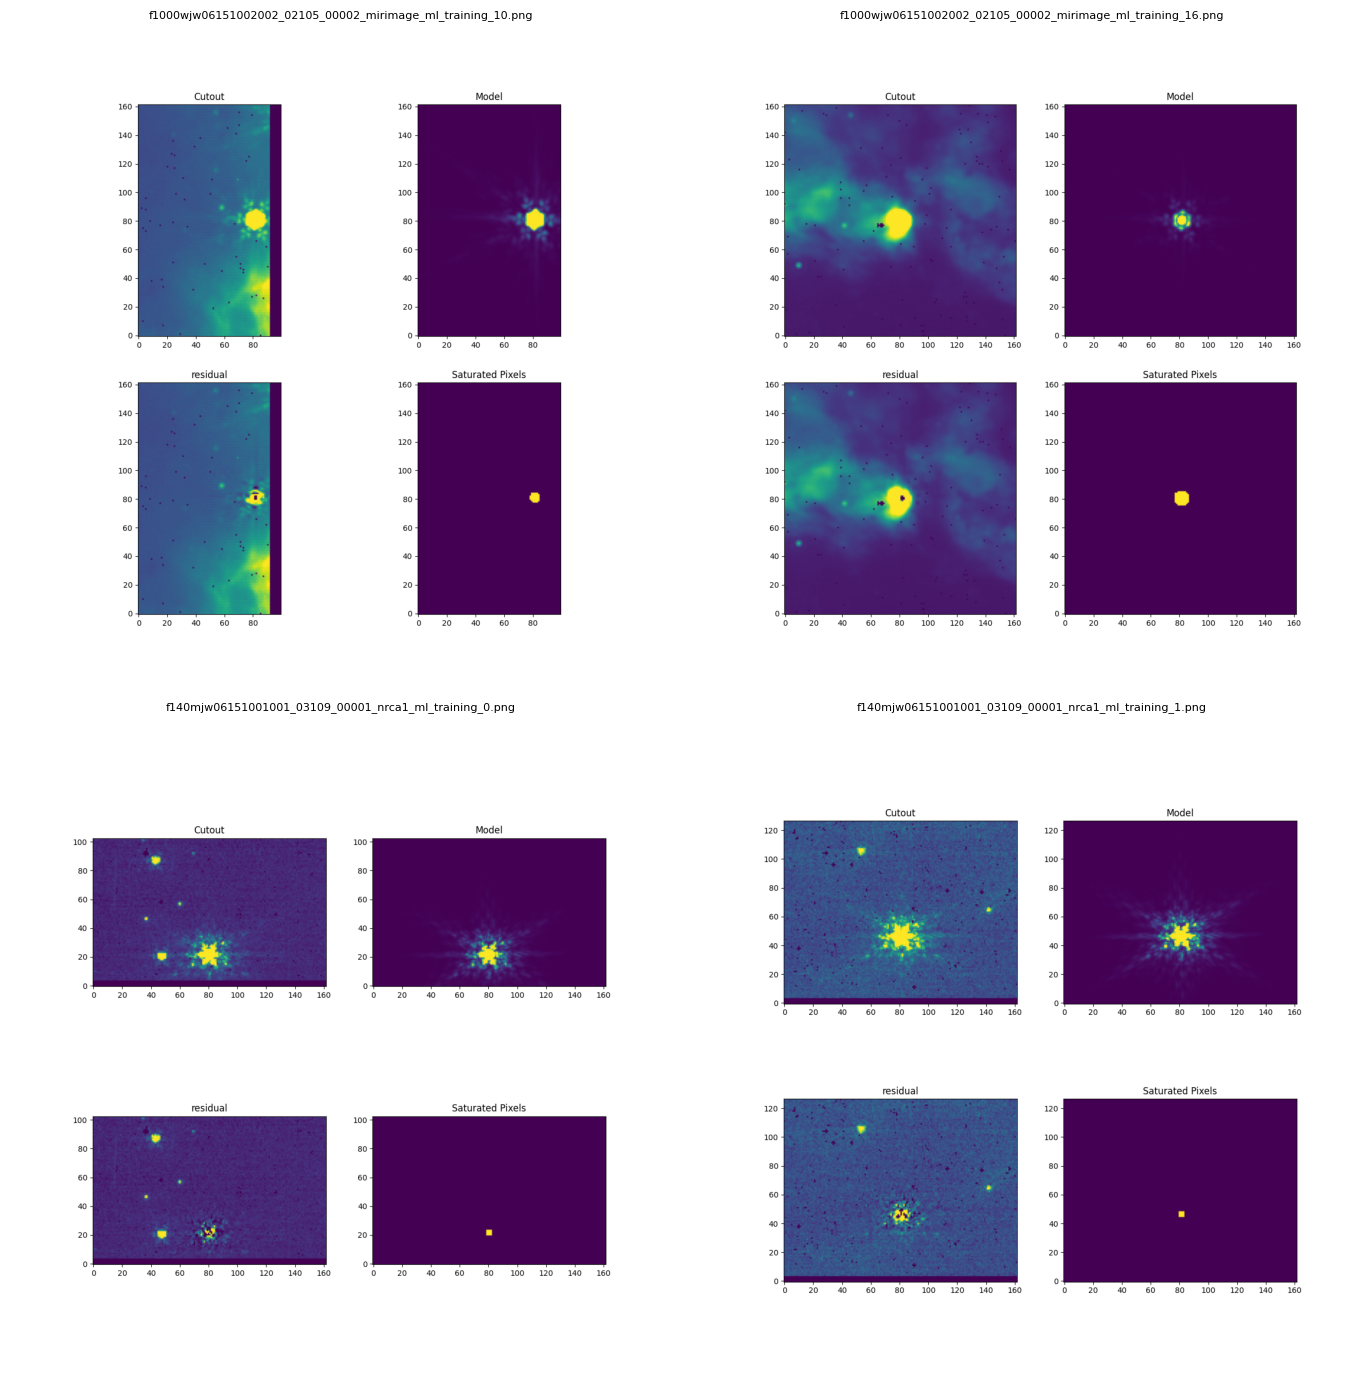

In [25]:
imgs = sorted(glob.glob(f'{V2}/cutout_img/*.png'))
print(len(imgs), 'diagnostic plots')
picks = [p for p in imgs if 'mirimage' in p][:2] + [p for p in imgs if 'nrc' in p][:2]
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, p in zip(axes.flat, picks):
    ax.imshow(plt.imread(p)); ax.set_title(os.path.basename(p), fontsize=8); ax.axis('off')
plt.tight_layout()

**Reading (v2).**

* **Labels stay on the fitted source.** 87% of rows lie within 5 px of the fit center (40% in June), and the largest source has 3,176 saturated pixels (11,452 in June). v2 has 1.18 M rows from 31,454 sources.
* **NIRCam labels agree with the pipeline slope.** Where the slope comes from unsaturated groups, the median PSF-fit label / `cal` value is 0.98-1.01 at every `sat_level`, with a 16-84% range of about +-10-15%. Without `local_bkg` the median falls from 0.94 to 0.82 as the level rises, so adding the background removes that trend.
* **MIRI labels run about 25% low.** The median is 0.74-0.79 at `sat_level` 1-3, with a 16-84% range of 0.44-1.08. The deficit depends on `area_ratio` (median 0.94 at ratio <= 1, 0.67 at 2-4), so it grows for less compact saturated regions. Possible causes, not yet tested: the stpsf MIRI model (the broad wings and cruciform artifact at short wavelengths), the 15-30 px background annulus sitting inside the MIRI PSF wings, and the one-pixel `n_pix_grow_sat` neighbours that the satstep run flags as saturated.
* **Skipped sources.** Of 62,714 candidates, 31,776 are kept. The largest skip reasons are a faint model (14,907) and the HOT-pixel check (11,052, about 18% of candidates). The "flux change > 20%" check never fires: it compares sums over the unsaturated pixels, which the replacement does not change.
* **Class balance.** Level 0 has 46,520 rows (2,091 sources), and MIRI still has no level 4 by construction. MIRI supplies only 1-3% of the rows at each level.


## 9. Next steps

- [x] Commit the `making_training_set.py` and run-script changes
- [x] Choose one Detector1 configuration for MIRI ramps (`jwst_new_cal_claude` settings with `saturation` on)
- [x] Regenerate the training set for all 15 filters
- [x] Find why the PSF-fit table has no MIRI level-4 rows (cal DQ never flags group-4-only saturation)
- [x] Add `local_bkg` to the labels (ramp = source + background)
- [ ] Find the ~25% MIRI label deficit: test the stpsf model, the background annulus size, and `n_pix_grow_sat` neighbours
- [ ] Fix or remove the "flux change > 20%" check (it compares pixels the replacement does not touch)
- [ ] Review diagnostic plots with `area_ratio` between 5 and 10 and adjust the 8.0 threshold
- [ ] Decide how to treat level-0 pixels: drop, down-weight, or keep for NIRCam only
- [ ] Add pane-truth rows for MIRI with a `label_source` column; compare with PSF-fit labels where both exist
- [ ] Check whether the HOT-pixel check is too strict
- [ ] Apply per-source caps and per-level balancing when assembling the gradient-boosting input